# Climate Champions: Overall Findings

This notebook consolidates the five workshop tracks into one descriptive
report using the processed participant data and answer-key reference.

## Analysis rules

Primary results use participants with valid A–D responses to all included
questions in both assessment phases.

Teachers, Scratch, micro:bit Heat, and micro:bit Flood use five questions.
Arduino uses Q1–Q4 because the Q5 answer key remains unresolved.

Scratch and both micro:bit tracks use identical pre/post questions.
Teachers and Arduino use related but different questions.

## Reading the comparisons

Percentages describe performance on each track's own assessment.
They are not a common proficiency scale: participants, questions,
difficulty, and—in Arduino's case—the number of included questions differ.

The figures are descriptive comparisons, not rankings of workshop
effectiveness. No single pooled learning-gain score is calculated.

Original workbook scoring is reported separately to show the effects
of the unresolved responses and Arduino answer key.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/processed. Open this notebook inside your project."
    )

DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures" / "overall"
TABLES = ROOT / "outputs" / "tables" / "overall"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

PRE_COLOR = "#7952B3"
POST_COLOR = "#E88932"

CONFIG = {
    "teachers": {
        "label": "Teachers",
        "questions": 5,
        "identical_items": False,
    },
    "scratch": {
        "label": "Scratch",
        "questions": 5,
        "identical_items": True,
    },
    "microbit_heat": {
        "label": "micro:bit Heat",
        "questions": 5,
        "identical_items": True,
    },
    "microbit_flood": {
        "label": "micro:bit Flood",
        "questions": 5,
        "identical_items": True,
    },
    "arduino": {
        "label": "Arduino",
        "questions": 4,
        "identical_items": False,
    },
}

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def markdown_table(frame):
    # Avoid requiring the optional tabulate package.
    clean = frame.astype(str).apply(
        lambda col: col.str.replace("|", "/", regex=False)
                       .str.replace("\n", " ", regex=False)
    )
    header = "| " + " | ".join(clean.columns) + " |"
    divider = "| " + " | ".join(["---"] * len(clean.columns)) + " |"
    rows = [
        "| " + " | ".join(row) + " |"
        for row in clean.itertuples(index=False, name=None)
    ]
    return "\n".join([header, divider, *rows])

print("Data folder:", DATA)

Data folder: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\data\processed


In [2]:
required_files = [
    *(f"{track}.csv" for track in CONFIG),
    "question_reference.csv",
]

missing = [name for name in required_files if not (DATA / name).exists()]

if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

reference = pd.read_csv(DATA / "question_reference.csv")

reference["phase"] = (
    reference["phase"].astype(str).str.strip().str.lower()
)
reference["question_number"] = pd.to_numeric(
    reference["question"].astype(str).str.extract(r"(\d+)", expand=False),
    errors="raise",
).astype(int)
reference["answer_key_raw"] = (
    reference["answer_key_raw"].astype("string").str.strip().str.upper()
)

datasets = {
    track: pd.read_csv(
        DATA / f"{track}.csv",
        dtype={"participant_id": "string"},
    )
    for track in CONFIG
}

display(pd.DataFrame([
    {
        "track": CONFIG[track]["label"],
        "source_records": len(frame),
        "primary_questions": CONFIG[track]["questions"],
        "identical_pre_post_items": CONFIG[track]["identical_items"],
    }
    for track, frame in datasets.items()
]))

,track,source_records,primary_questions,identical_pre_post_items
0,Teachers,29,5,False
1,Scratch,22,5,True
2,micro:bit Heat,25,5,True
3,micro:bit Flood,26,5,True
4,Arduino,27,4,False


## Validation and scoring

Scores are recalculated from participant responses and the relevant
answer keys. Unresolved responses are retained in the audit table.

The primary comparison uses the same participants in both phases.
Arduino Q5 is excluded for everyone; an unresolved Q5 response alone
does not exclude a participant from Arduino's Q1–Q4 analysis.

Workbook scores are reconstructed separately using exact answer-key
matching and verified against all five stored scoring fields.

In [3]:
summary_rows = []
participant_frames = []
audit_frames = []
item_rows = []
verification_rows = []
comparison_rows = []

all_answer_cols = [
    f"{phase}_q{q}"
    for phase in ["pre", "post"]
    for q in range(1, 6)
]

workbook_mapping = {
    "pre_correct": "pre_correct_workbook",
    "post_correct": "post_correct_workbook",
    "pre_score_pct": "pre_score_pct_workbook",
    "post_score_pct": "post_score_pct_workbook",
    "change_pp": "change_pp_workbook",
}

for track, config in CONFIG.items():
    frame = datasets[track]
    label = config["label"]
    question_count = config["questions"]

    required = [
        "participant_id", "track",
        *all_answer_cols,
        *workbook_mapping.values(),
    ]
    absent = [c for c in required if c not in frame.columns]

    if absent:
        raise ValueError(f"{label}: missing columns {absent}")
    if frame.empty:
        raise ValueError(f"{label}: empty dataset")
    if frame["participant_id"].fillna("").str.strip().eq("").any():
        raise ValueError(f"{label}: missing IDs")
    if frame["participant_id"].duplicated().any():
        raise ValueError(f"{label}: duplicate IDs")
    if not frame["track"].eq(track).all():
        raise ValueError(f"{label}: unexpected track values")

    keys = reference.loc[reference["track"].eq(track)].copy()
    expected = {
        (phase, q)
        for phase in ["pre", "post"]
        for q in range(1, 6)
    }

    if (
        len(keys) != 10
        or set(zip(keys["phase"], keys["question_number"])) != expected
    ):
        raise ValueError(f"{label}: incomplete or duplicate answer keys")

    key_map = keys.set_index(
        ["phase", "question_number"]
    )["answer_key_raw"]
    skill_map = keys.set_index(
        ["phase", "question_number"]
    )["skill"]

    primary_keys = keys.loc[
        keys["question_number"].le(question_count), "answer_key_raw"
    ]
    if not primary_keys.isin(list("ABCD")).all():
        raise ValueError(f"{label}: unresolved primary answer key")

    if track == "arduino":
        if not keys.loc[
            keys["question_number"].eq(5), "answer_key_raw"
        ].eq("ABCD").all():
            raise ValueError(
                "Arduino Q5 key changed. Review the analysis policy."
            )

    if config["identical_items"]:
        for q in range(1, question_count + 1):
            if key_map[("pre", q)] != key_map[("post", q)]:
                raise ValueError(f"{label}: pre/post key mismatch in Q{q}")

    answers = frame[all_answer_cols].apply(
        lambda col: col.astype("string").str.strip().str.upper()
    )
    valid = answers.isin(list("ABCD"))

    primary_cols = [
        f"{phase}_q{q}"
        for phase in ["pre", "post"]
        for q in range(1, question_count + 1)
    ]
    included = valid[primary_cols].all(axis=1)

    if not included.any():
        raise ValueError(f"{label}: no complete primary pairs")

    audit = frame[["participant_id"]].copy()
    audit["track"] = track
    audit["included_in_primary"] = included
    audit["unresolved_primary_answers"] = (~valid[primary_cols]).sum(axis=1)
    audit["unresolved_all_answers"] = (~valid).sum(axis=1)
    audit["q5_excluded_due_to_key"] = track == "arduino"
    audit_frames.append(audit)

    paired = frame.loc[included, ["participant_id"]].copy()
    paired["track"] = track
    paired["questions_scored"] = question_count

    for phase in ["pre", "post"]:
        paired[f"{phase}_correct"] = sum(
            answers.loc[included, f"{phase}_q{q}"]
            .eq(key_map[(phase, q)])
            .astype(int)
            for q in range(1, question_count + 1)
        )
        paired[f"{phase}_score_pct"] = (
            paired[f"{phase}_correct"] / question_count * 100
        )

    paired["change_pp"] = (
        paired["post_score_pct"] - paired["pre_score_pct"]
    )
    paired["change_group"] = np.select(
        [paired["change_pp"].gt(0), paired["change_pp"].lt(0)],
        ["Higher", "Lower"],
        default="Unchanged",
    )
    participant_frames.append(paired)

    n = len(paired)
    row = {
        "track": track,
        "track_label": label,
        "source_records": len(frame),
        "primary_n": n,
        "excluded_records": len(frame) - n,
        "questions_scored": question_count,
        "identical_items": config["identical_items"],
        "pre_mean_pct": paired["pre_score_pct"].mean(),
        "post_mean_pct": paired["post_score_pct"].mean(),
        "mean_change_pp": paired["change_pp"].mean(),
    }

    for group in ["Higher", "Unchanged", "Lower"]:
        count = int(paired["change_group"].eq(group).sum())
        row[f"{group.lower()}_n"] = count
        row[f"{group.lower()}_pct"] = count / n * 100

    summary_rows.append(row)

    for q in range(1, question_count + 1):
        item = {
            "track": track,
            "track_label": label,
            "question": f"Q{q}",
            "primary_n": n,
            "identical_items": config["identical_items"],
        }
        for phase in ["pre", "post"]:
            correct = int(
                answers.loc[included, f"{phase}_q{q}"]
                .eq(key_map[(phase, q)]).sum()
            )
            item[f"{phase}_skill"] = skill_map[(phase, q)]
            item[f"{phase}_correct"] = correct
            item[f"{phase}_pct"] = correct / n * 100
        item_rows.append(item)

    # Reconstruct original five-question exact-match scoring.
    literal = pd.DataFrame(index=frame.index)
    for phase in ["pre", "post"]:
        literal[f"{phase}_correct"] = sum(
            answers[f"{phase}_q{q}"]
            .eq(key_map[(phase, q)])
            .fillna(False)
            .astype(int)
            for q in range(1, 6)
        )
        literal[f"{phase}_score_pct"] = literal[f"{phase}_correct"] * 20

    literal["change_pp"] = (
        literal["post_score_pct"] - literal["pre_score_pct"]
    )

    for calculated, stored in workbook_mapping.items():
        matches = np.isclose(
            literal[calculated].to_numpy(dtype=float),
            pd.to_numeric(frame[stored], errors="coerce").to_numpy(dtype=float),
            atol=1e-8,
            equal_nan=False,
        )
        verification_rows.append({
            "track": track,
            "field": stored,
            "matching": int(matches.sum()),
            "mismatching_or_missing": int((~matches).sum()),
        })

    for method, group, denominator in [
        ("Primary", paired, question_count),
        ("Workbook scoring — same primary group", literal.loc[included], 5),
        ("Workbook scoring — all records", literal, 5),
    ]:
        comparison_rows.append({
            "track": track,
            "track_label": label,
            "method": method,
            "n": len(group),
            "questions_in_denominator": denominator,
            "pre_mean_pct": group["pre_score_pct"].mean(),
            "post_mean_pct": group["post_score_pct"].mean(),
            "mean_change_pp": group["change_pp"].mean(),
        })

summary = pd.DataFrame(summary_rows)
participants = pd.concat(participant_frames, ignore_index=True)
audit = pd.concat(audit_frames, ignore_index=True)
items = pd.DataFrame(item_rows)
verification = pd.DataFrame(verification_rows)
scoring_comparison = pd.DataFrame(comparison_rows)

display(verification)

if verification["mismatching_or_missing"].sum():
    raise ValueError("Workbook scoring mismatch. Review before continuing.")

print("All workbook scoring checks matched.")
display(summary.round(2))

,track,field,matching,mismatching_or_missing
0,teachers,pre_correct_workbook,29,0
1,teachers,post_correct_workbook,29,0
2,teachers,pre_score_pct_workbook,29,0
3,teachers,post_score_pct_workbook,29,0
4,teachers,change_pp_workbook,29,0
5,scratch,pre_correct_workbook,22,0
6,scratch,post_correct_workbook,22,0
7,scratch,pre_score_pct_workbook,22,0
8,scratch,post_score_pct_workbook,22,0
9,scratch,change_pp_workbook,22,0


All workbook scoring checks matched.


,track,track_label,source_records,primary_n,excluded_records,questions_scored,identical_items,pre_mean_pct,post_mean_pct,mean_change_pp,higher_n,higher_pct,unchanged_n,unchanged_pct,lower_n,lower_pct
0,teachers,Teachers,29,29,0,5,False,25.52,55.86,30.34,22,75.86,6,20.69,1,3.45
1,scratch,Scratch,22,22,0,5,True,50.00,75.45,25.45,21,95.45,0,0.00,1,4.55
2,microbit_heat,micro:bit Heat,25,25,0,5,True,47.20,58.40,11.20,13,52.00,8,32.00,4,16.00
3,microbit_flood,micro:bit Flood,26,25,1,5,True,67.20,66.40,-0.80,7,28.00,12,48.00,6,24.00
4,arduino,Arduino,27,26,1,4,False,54.81,72.12,17.31,19,73.08,4,15.38,3,11.54


## Participation and primary assessment results

The participation figure shows how many records support each primary
comparison and how many are excluded because of unresolved responses.

Average scores and participant score differences are shown in the
original track order. They should be interpreted within each assessment,
not as a ranking of tracks.

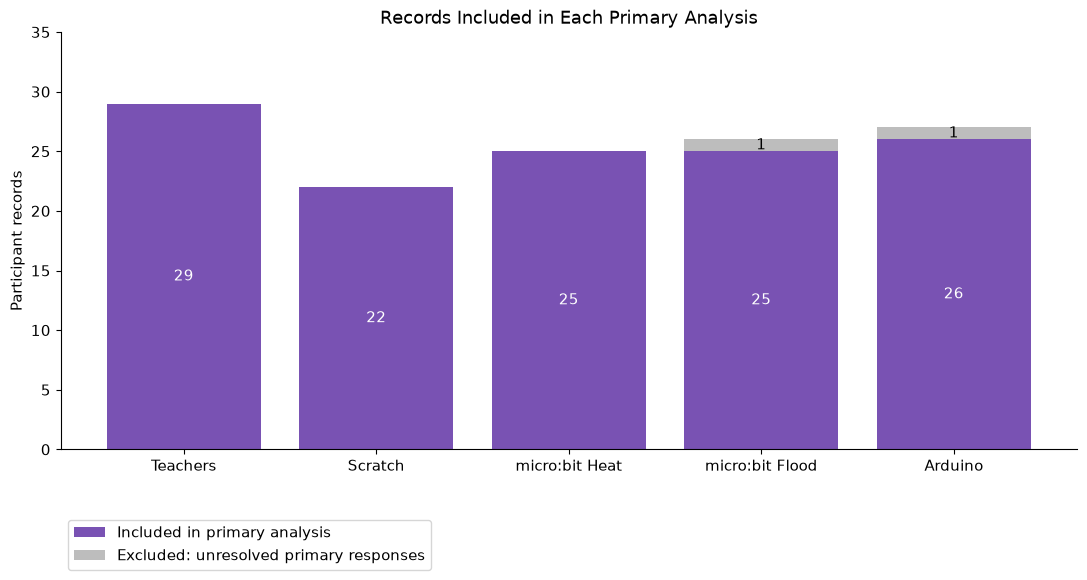

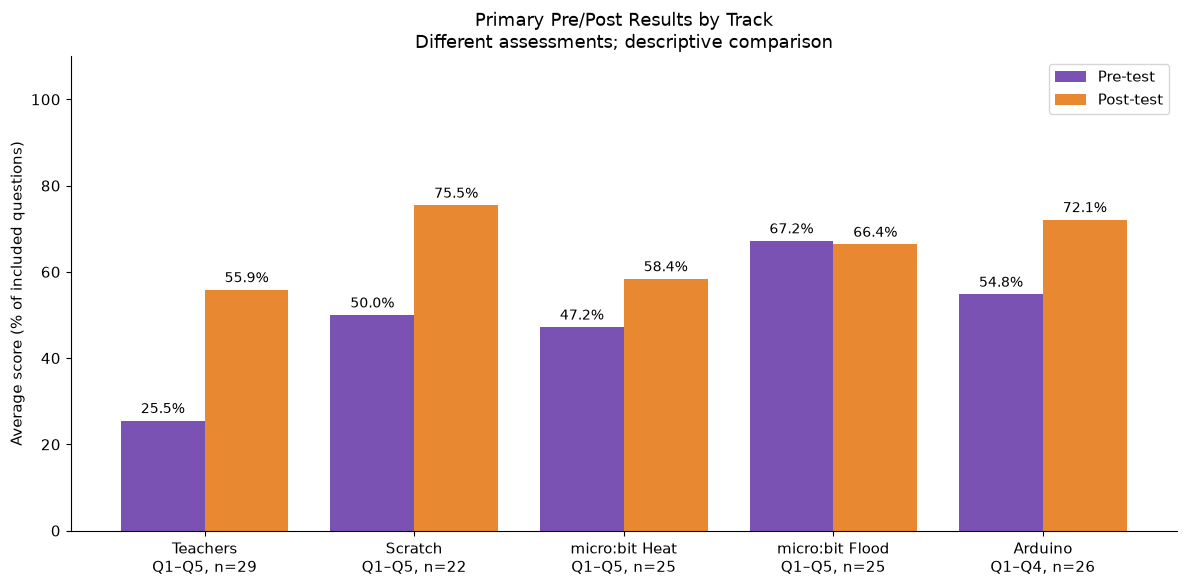

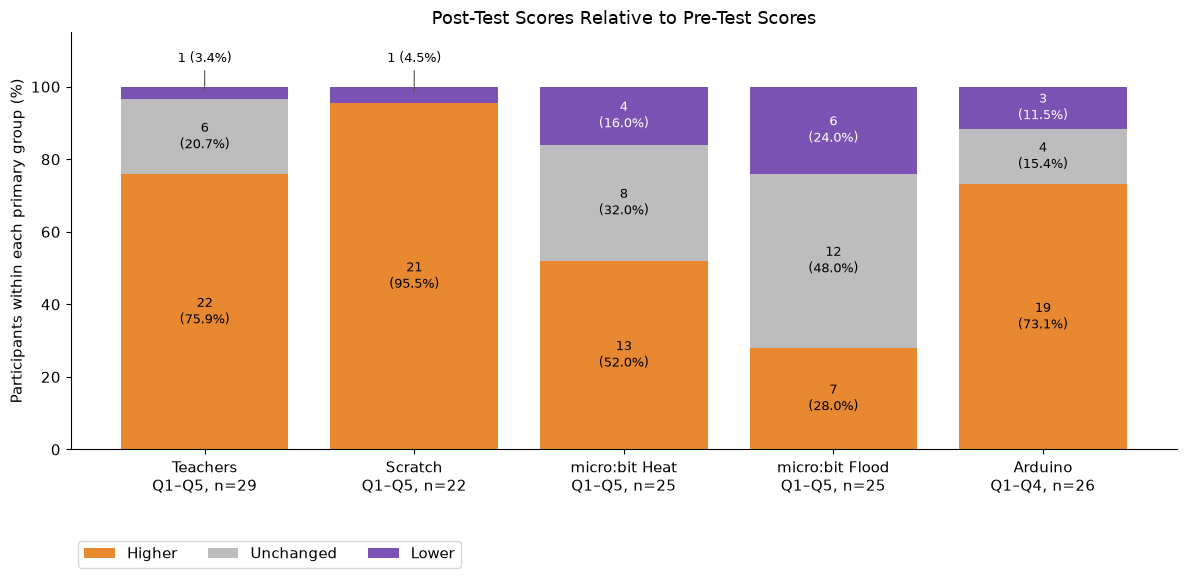

In [9]:
labels = [
    f"{r.track_label}\nQ1–Q{r.questions_scored}, n={r.primary_n}"
    for r in summary.itertuples()
]
x = np.arange(len(summary))

# Figure 1: included and excluded records
fig, ax = plt.subplots(figsize=(11, 6))

included_bars = ax.bar(
    x, summary["primary_n"],
    color=PRE_COLOR, label="Included in primary analysis",
)
excluded_bars = ax.bar(
    x, summary["excluded_records"],
    bottom=summary["primary_n"],
    color="#BDBDBD", label="Excluded: unresolved primary responses",
)

ax.bar_label(included_bars, label_type="center", color="white")
ax.bar_label(
    excluded_bars,
    labels=[str(v) if v else "" for v in summary["excluded_records"]],
    label_type="center",
)

ax.set_xticks(x, summary["track_label"])
ax.set_ylim(0, summary["source_records"].max() + 6)
ax.set_ylabel("Participant records")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.set_title("Records Included in Each Primary Analysis")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15))
save_figure(fig, "01_analysis_coverage.png")

# Figure 2: average scores
fig, ax = plt.subplots(figsize=(12, 6))

for offset, column, label, color in [
    (-0.2, "pre_mean_pct", "Pre-test", PRE_COLOR),
    (0.2, "post_mean_pct", "Post-test", POST_COLOR),
]:
    bars = ax.bar(
        x + offset, summary[column], width=0.4,
        color=color, label=label,
    )
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=10)

ax.set_xticks(x, labels)
ax.set_ylim(0, 110)
ax.set_ylabel("Average score (% of included questions)")
ax.set_title("Primary Pre/Post Results by Track\nDifferent assessments; descriptive comparison")
ax.legend()
save_figure(fig, "02_track_average_scores.png")

# Figure 3: participant score differences
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(summary))

for group, color in [
    ("Higher", POST_COLOR),
    ("Unchanged", "#BDBDBD"),
    ("Lower", PRE_COLOR),
]:
    values = summary[f"{group.lower()}_pct"].to_numpy()
    counts = summary[f"{group.lower()}_n"].to_numpy()

    ax.bar(
        x, values, bottom=bottom,
        color=color, label=group,
    )

    for i, (count, pct, base) in enumerate(zip(counts, values, bottom)):
        if count == 0:
            continue

        if pct < 8:
            # Put small-segment labels above the bar.
            ax.annotate(
                f"{count} ({pct:.1f}%)",
                xy=(i, base + pct / 2),
                xytext=(i, 106),
                ha="center",
                va="bottom",
                fontsize=9,
                arrowprops={
                    "arrowstyle": "-",
                    "color": "#555555",
                    "linewidth": 0.8,
                },
            )
        else:
            ax.text(
                i, base + pct / 2,
                f"{count}\n({pct:.1f}%)",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if group == "Lower" else "black",
            )

    bottom += values

ax.set_xticks(x, labels)
ax.set_ylim(0, 115)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_ylabel("Participants within each primary group (%)")
ax.set_title("Post-Test Scores Relative to Pre-Test Scores")
ax.legend(
    loc="upper left",
    bbox_to_anchor=(0, -0.2),
    ncol=3,
)

save_figure(fig, "03_participant_score_differences.png")



## Scoring sensitivity and question-level priorities

Flood's primary results exclude the unresolved response pair.
Arduino's primary results also omit Q5 and use a four-question denominator.

The scoring comparison distinguishes the effect of changing the included
group from the effect of changing the denominator.

The lowest post-test items identify relative priorities within each
track. They are not a common measure of skill across tracks, and a single
question does not establish mastery or lack of mastery.

,track,track_label,method,n,questions_in_denominator,pre_mean_pct,post_mean_pct,mean_change_pp
0,teachers,Teachers,Primary,29,5,25.52,55.86,30.34
1,teachers,Teachers,Workbook scoring — same primary group,29,5,25.52,55.86,30.34
2,teachers,Teachers,Workbook scoring — all records,29,5,25.52,55.86,30.34
3,scratch,Scratch,Primary,22,5,50.00,75.45,25.45
4,scratch,Scratch,Workbook scoring — same primary group,22,5,50.00,75.45,25.45
5,scratch,Scratch,Workbook scoring — all records,22,5,50.00,75.45,25.45
6,microbit_heat,micro:bit Heat,Primary,25,5,47.20,58.40,11.20
7,microbit_heat,micro:bit Heat,Workbook scoring — same primary group,25,5,47.20,58.40,11.20
8,microbit_heat,micro:bit Heat,Workbook scoring — all records,25,5,47.20,58.40,11.20
9,microbit_flood,micro:bit Flood,Primary,25,5,67.20,66.40,-0.80


,track_label,question,post_skill,post_correct,primary_n,post_pct
0,Teachers,Q1,Abstraction,9,29,31.03
7,Scratch,Q3,Abstraction,10,22,45.45
10,micro:bit Heat,Q1,Decomposition,9,25,36.00
12,micro:bit Heat,Q3,Abstraction,9,25,36.00
17,micro:bit Flood,Q3,Abstraction,1,25,4.00
21,Arduino,Q2,"Hardware: PWM output (analogWrite) range, 0–255",15,26,57.69


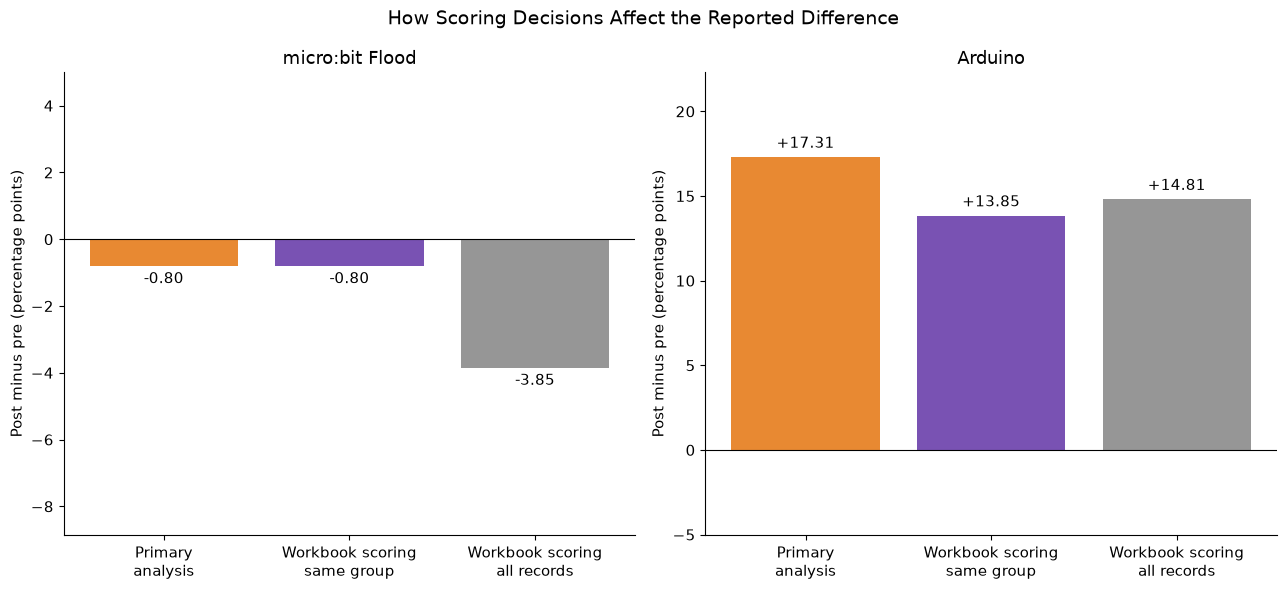

In [5]:
display(scoring_comparison.round(2))

# Keep all ties for the lowest post-test item within a track.
minimum_post = items.groupby("track")["post_pct"].transform("min")
priorities = items.loc[items["post_pct"].eq(minimum_post)].copy()

display(priorities[[
    "track_label",
    "question",
    "post_skill",
    "post_correct",
    "primary_n",
    "post_pct",
]].round(2))

# Figure 4: scoring choices for the two affected tracks
methods = [
    "Primary",
    "Workbook scoring — same primary group",
    "Workbook scoring — all records",
]
method_labels = [
    "Primary\nanalysis",
    "Workbook scoring\nsame group",
    "Workbook scoring\nall records",
]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, track in zip(axes, ["microbit_flood", "arduino"]):
    selected = (
        scoring_comparison.loc[scoring_comparison["track"].eq(track)]
        .set_index("method").loc[methods]
    )
    values = selected["mean_change_pp"].to_numpy()

    bars = ax.bar(
        np.arange(3), values,
        color=[POST_COLOR, PRE_COLOR, "#969696"],
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.bar_label(bars, fmt="%+.2f", padding=4)
    ax.set_xticks(np.arange(3), method_labels)
    ax.set_ylim(min(0, values.min()) - 5, max(0, values.max()) + 5)
    ax.set_ylabel("Post minus pre (percentage points)")
    ax.set_title(CONFIG[track]["label"])

fig.suptitle("How Scoring Decisions Affect the Reported Difference", fontsize=14)
save_figure(fig, "04_scoring_sensitivity.png")

In [6]:
report_table = pd.DataFrame({
    "Track": summary["track_label"],
    "Included / source": [
        f"{r.primary_n}/{r.source_records}"
        for r in summary.itertuples()
    ],
    "Questions": summary["questions_scored"].astype(str),
    "Pre": summary["pre_mean_pct"].map(lambda v: f"{v:.2f}%"),
    "Post": summary["post_mean_pct"].map(lambda v: f"{v:.2f}%"),
    "Difference": summary["mean_change_pp"].map(lambda v: f"{v:+.2f} pp"),
})

track_paragraphs = []

for r in summary.itertuples():
    comparability = (
        "This track used identical pre/post questions."
        if r.identical_items
        else "This track used related but different pre/post questions."
    )

    track_paragraphs.append(
        f"### {r.track_label}\n\n"
        f"Among **{r.primary_n} participants**, average scores were "
        f"**{r.pre_mean_pct:.2f}% before** and "
        f"**{r.post_mean_pct:.2f}% after**, a difference of "
        f"**{r.mean_change_pp:+.2f} percentage points**.\n\n"
        f"**{r.higher_n}** participants scored higher, "
        f"**{r.unchanged_n}** had unchanged scores, and "
        f"**{r.lower_n}** scored lower. {comparability}"
    )

priority_lines = "\n".join(
    f"- **{r.track_label}, {r.question}:** {r.post_skill}. "
    f"Post-test correctness was **{r.post_correct}/{r.primary_n} "
    f"({r.post_pct:.1f}%)**."
    for r in priorities.itertuples()
)

total_records = int(summary["source_records"].sum())
included_records = int(summary["primary_n"].sum())
excluded_records = int(summary["excluded_records"].sum())

findings_md = f"""
## Overall findings

The five source datasets contain **{total_records} participant-track
records**. Primary analyses include **{included_records} records** and
exclude **{excluded_records} records** with unresolved responses in the
questions being scored.

These totals describe records across tracks. They do not independently
verify the number of unique people across the entire program.

### Primary results

{markdown_table(report_table)}

Here, pp means percentage points. Arduino results use four questions;
the other tracks use five.

{chr(10).join(track_paragraphs)}

## Question-level priorities

The following items had the lowest post-test correctness within their
respective tracks. All ties are retained.

{priority_lines}

Review question wording, answer keys, and selected responses alongside
these rates before attributing them solely to learning difficulties.

## Interpretation across tracks

The results show different patterns across the five assessments.
Higher group averages do not mean every participant improved, and a
nearly unchanged average can conceal improvements on some questions and
decreases on others.

Track differences cannot establish which workshop was most effective.
The tracks assessed different content and involved different groups.
Arduino also uses fewer scored questions in the primary analysis.

No pooled score is presented because combining these percentages could
obscure differences in assessment content and scoring.
"""

display(Markdown(findings_md))


## Overall findings

The five source datasets contain **129 participant-track
records**. Primary analyses include **127 records** and
exclude **2 records** with unresolved responses in the
questions being scored.

These totals describe records across tracks. They do not independently
verify the number of unique people across the entire program.

### Primary results

| Track | Included / source | Questions | Pre | Post | Difference |
| --- | --- | --- | --- | --- | --- |
| Teachers | 29/29 | 5 | 25.52% | 55.86% | +30.34 pp |
| Scratch | 22/22 | 5 | 50.00% | 75.45% | +25.45 pp |
| micro:bit Heat | 25/25 | 5 | 47.20% | 58.40% | +11.20 pp |
| micro:bit Flood | 25/26 | 5 | 67.20% | 66.40% | -0.80 pp |
| Arduino | 26/27 | 4 | 54.81% | 72.12% | +17.31 pp |

Here, pp means percentage points. Arduino results use four questions;
the other tracks use five.

### Teachers

Among **29 participants**, average scores were **25.52% before** and **55.86% after**, a difference of **+30.34 percentage points**.

**22** participants scored higher, **6** had unchanged scores, and **1** scored lower. This track used related but different pre/post questions.
### Scratch

Among **22 participants**, average scores were **50.00% before** and **75.45% after**, a difference of **+25.45 percentage points**.

**21** participants scored higher, **0** had unchanged scores, and **1** scored lower. This track used identical pre/post questions.
### micro:bit Heat

Among **25 participants**, average scores were **47.20% before** and **58.40% after**, a difference of **+11.20 percentage points**.

**13** participants scored higher, **8** had unchanged scores, and **4** scored lower. This track used identical pre/post questions.
### micro:bit Flood

Among **25 participants**, average scores were **67.20% before** and **66.40% after**, a difference of **-0.80 percentage points**.

**7** participants scored higher, **12** had unchanged scores, and **6** scored lower. This track used identical pre/post questions.
### Arduino

Among **26 participants**, average scores were **54.81% before** and **72.12% after**, a difference of **+17.31 percentage points**.

**19** participants scored higher, **4** had unchanged scores, and **3** scored lower. This track used related but different pre/post questions.

## Question-level priorities

The following items had the lowest post-test correctness within their
respective tracks. All ties are retained.

- **Teachers, Q1:** Abstraction. Post-test correctness was **9/29 (31.0%)**.
- **Scratch, Q3:** Abstraction. Post-test correctness was **10/22 (45.5%)**.
- **micro:bit Heat, Q1:** Decomposition. Post-test correctness was **9/25 (36.0%)**.
- **micro:bit Heat, Q3:** Abstraction. Post-test correctness was **9/25 (36.0%)**.
- **micro:bit Flood, Q3:** Abstraction. Post-test correctness was **1/25 (4.0%)**.
- **Arduino, Q2:** Hardware: PWM output (analogWrite) range, 0–255. Post-test correctness was **15/26 (57.7%)**.

Review question wording, answer keys, and selected responses alongside
these rates before attributing them solely to learning difficulties.

## Interpretation across tracks

The results show different patterns across the five assessments.
Higher group averages do not mean every participant improved, and a
nearly unchanged average can conceal improvements on some questions and
decreases on others.

Track differences cannot establish which workshop was most effective.
The tracks assessed different content and involved different groups.
Arduino also uses fewer scored questions in the primary analysis.

No pooled score is presented because combining these percentages could
obscure differences in assessment content and scoring.


In [7]:
flood_primary = scoring_comparison.loc[
    scoring_comparison["track"].eq("microbit_flood")
    & scoring_comparison["method"].eq("Primary")
].iloc[0]

flood_workbook = scoring_comparison.loc[
    scoring_comparison["track"].eq("microbit_flood")
    & scoring_comparison["method"].eq("Workbook scoring — all records")
].iloc[0]

arduino_primary = scoring_comparison.loc[
    scoring_comparison["track"].eq("arduino")
    & scoring_comparison["method"].eq("Primary")
].iloc[0]

arduino_workbook = scoring_comparison.loc[
    scoring_comparison["track"].eq("arduino")
    & scoring_comparison["method"].eq("Workbook scoring — all records")
].iloc[0]

recommendations_md = f"""
## Data-quality decisions

### micro:bit Flood

The primary analysis contains **{int(flood_primary["n"])} participants**
and shows a difference of
**{flood_primary["mean_change_pp"]:+.2f} percentage points**.

The workbook calculation includes **{int(flood_workbook["n"])} participants**
and treats X responses as incorrect, producing
**{flood_workbook["mean_change_pp"]:+.2f} percentage points**.

The meaning of X remains unresolved. Keep both calculations labeled
and use the complete-pair result as the primary finding.

### Arduino

The primary Q1–Q4 analysis contains **{int(arduino_primary["n"])} participants**
and shows a difference of
**{arduino_primary["mean_change_pp"]:+.2f} percentage points**.

The original workbook calculation uses five questions and
**{int(arduino_workbook["n"])} participants**, producing
**{arduino_workbook["mean_change_pp"]:+.2f} percentage points**.

These differences reflect both scoring and inclusion decisions.
The ABCD key for Q5 must be clarified before reporting a validated
full-assessment result.

## Recommendations

1. **Prioritize the identified post-test difficulties.**
   Use the question-level table to select focused practice activities.
   Review both the item and its answer choices before drawing conclusions.

2. **Resolve the outstanding scoring issues.**
   Confirm X responses and the intended Arduino Q5 scoring using original
   assessment records or the data owner. Document approved corrections.

3. **Strengthen future assessment design.**
   Use identical or demonstrably comparable pre/post questions when
   estimating change. Include multiple questions per skill and a practical
   task to reduce reliance on a single item.

4. **Assess retention.**
   Add a later assessment to examine whether participants retain and apply
   the concepts beyond the immediate post-test.

5. **Keep report labels explicit.**
   Show sample size, questions scored, and any exclusions beside results.
   Avoid presenting differences between tracks as an effectiveness ranking.

## Limitations

The analysis uses small track-level samples and short assessments.
There is no comparison group, and question difficulty may differ between
phases and tracks. Repeated questions may also influence post-test results.

Some records or questions are excluded because their scoring is unresolved.
These decisions affect the population and content represented by the results.

The findings describe recorded assessment performance. They do not
establish causation, long-term retention, or complete mastery.

## Next stage: exploratory prediction

The prediction notebook will examine whether pre-test information helps
predict held-out participants' post-test scores.

Models should be evaluated separately by track initially, using the same
documented scoring definitions. Arduino's provisional target is the
post-test Q1–Q4 total.

Use participant-level validation, training-fold preprocessing, and simple
baselines. Do not use post-test answers or score differences as predictors.
Multiple answers from one participant must not be treated as independent
participants.

Report prediction error and variability. Predictive performance does not
measure the causal effectiveness of the workshops.
"""

display(Markdown(recommendations_md))


## Data-quality decisions

### micro:bit Flood

The primary analysis contains **25 participants**
and shows a difference of
**-0.80 percentage points**.

The workbook calculation includes **26 participants**
and treats X responses as incorrect, producing
**-3.85 percentage points**.

The meaning of X remains unresolved. Keep both calculations labeled
and use the complete-pair result as the primary finding.

### Arduino

The primary Q1–Q4 analysis contains **26 participants**
and shows a difference of
**+17.31 percentage points**.

The original workbook calculation uses five questions and
**27 participants**, producing
**+14.81 percentage points**.

These differences reflect both scoring and inclusion decisions.
The ABCD key for Q5 must be clarified before reporting a validated
full-assessment result.

## Recommendations

1. **Prioritize the identified post-test difficulties.**
   Use the question-level table to select focused practice activities.
   Review both the item and its answer choices before drawing conclusions.

2. **Resolve the outstanding scoring issues.**
   Confirm X responses and the intended Arduino Q5 scoring using original
   assessment records or the data owner. Document approved corrections.

3. **Strengthen future assessment design.**
   Use identical or demonstrably comparable pre/post questions when
   estimating change. Include multiple questions per skill and a practical
   task to reduce reliance on a single item.

4. **Assess retention.**
   Add a later assessment to examine whether participants retain and apply
   the concepts beyond the immediate post-test.

5. **Keep report labels explicit.**
   Show sample size, questions scored, and any exclusions beside results.
   Avoid presenting differences between tracks as an effectiveness ranking.

## Limitations

The analysis uses small track-level samples and short assessments.
There is no comparison group, and question difficulty may differ between
phases and tracks. Repeated questions may also influence post-test results.

Some records or questions are excluded because their scoring is unresolved.
These decisions affect the population and content represented by the results.

The findings describe recorded assessment performance. They do not
establish causation, long-term retention, or complete mastery.

## Next stage: exploratory prediction

The prediction notebook will examine whether pre-test information helps
predict held-out participants' post-test scores.

Models should be evaluated separately by track initially, using the same
documented scoring definitions. Arduino's provisional target is the
post-test Q1–Q4 total.

Use participant-level validation, training-fold preprocessing, and simple
baselines. Do not use post-test answers or score differences as predictors.
Multiple answers from one participant must not be treated as independent
participants.

Report prediction error and variability. Predictive performance does not
measure the causal effectiveness of the workshops.


In [8]:
exports = {
    "primary_track_summary": summary,
    "primary_participant_scores": participants,
    "participant_audit": audit,
    "question_results": items,
    "lowest_post_items": priorities,
    "scoring_comparison": scoring_comparison,
    "workbook_verification": verification,
    "report_summary_table": report_table,
}

for name, table in exports.items():
    table.to_csv(
        TABLES / f"overall_{name}.csv",
        index=False,
    )

report_path = TABLES / "overall_findings.md"
report_path.write_text(
    findings_md + "\n\n" + recommendations_md,
    encoding="utf-8",
)

print(f"Saved {len(exports)} tables.")
print("Figures:", FIGURES)
print("Findings:", report_path)

Saved 8 tables.
Figures: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\figures\overall
Findings: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\tables\overall\overall_findings.md
